# Laboratorio 9 — Task 4: comparación generativa y pass@k

**Curso:** Deep Learning 10

**Autor:** Felipe Aguilar

Reutilizamos los pesos y las 500 muestras con $w=1$ de la Task 3.4.
Como no se incluyeron pesos del VAE en el repositorio, repetimos únicamente
el entrenamiento de $\beta=1$: misma arquitectura, semilla 3045, 20 épocas,
Adam con lr=0.001 y lotes de 128. Es una nueva ejecución, no los pesos
originales de la Task 1. Las definiciones del VAE y su entrenamiento se
copian directamente del notebook 01 al construir este documento.

In [1]:
from pathlib import Path
import json
import math
import platform
import random
import statistics
import sys
import time

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import Markdown, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.difusion import UNet, linear_schedule, sample
from src.evaluacion import horizontal_sharpness, pass_at_k

SEED, LATENT_DIM, BATCH_SIZE, EPOCHS, LR = 3045, 2, 128, 20, 1e-3
# CPU para el VAE, como en la Task 1; ambos tiempos se miden en este dispositivo.
DEVICE = torch.device("cpu")
torch.set_num_threads(4)
DATA_DIR = ROOT / "data"
CHECKPOINT_DIR = ROOT / "artifacts/task4"
OUTPUT_DIR = ROOT / "outputs/task4"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print(f"Semilla: {SEED} | Dispositivo: {DEVICE} | Hilos: {torch.get_num_threads()}")
print(f"Sistema: {platform.platform()} | PyTorch: {torch.__version__}")

Semilla: 3045 | Dispositivo: cpu | Hilos: 4
Sistema: macOS-26.6.2-arm64-arm-64bit | PyTorch: 2.13.0


## Preparación del VAE de β=1

In [2]:
full_train = datasets.FashionMNIST(DATA_DIR, train=True, download=True,
                                  transform=transforms.ToTensor())
train_set = Subset(full_train, range(55_000))
val_set = Subset(full_train, range(55_000, 60_000))

def make_train_loader(seed=SEED):
    return DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(seed), num_workers=0)

val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
print(f"Entrenamiento: {len(train_set)} | Validación: {len(val_set)}")

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<02:03, 214kB/s]

  0%|          | 65.5k/26.4M [00:00<02:08, 205kB/s]

  0%|          | 131k/26.4M [00:00<01:34, 278kB/s] 

  1%|          | 229k/26.4M [00:00<01:04, 404kB/s]

...

 84%|████████▎ | 3.70M/4.42M [00:01<00:00, 4.98MB/s]

100%|██████████| 4.42M/4.42M [00:01<00:00, 3.05MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 19.7MB/s]

Entrenamiento: 55000 | Validación: 5000


In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim: int = LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 400),
            nn.ReLU(),
        )
        self.mu_head = nn.Linear(400, latent_dim)
        self.logvar_head = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 400),
            nn.ReLU(),
            nn.Linear(400, 28 * 28),
            nn.Sigmoid(),
        )

    def encode(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        h = self.encoder(x)
        return self.mu_head(h), self.logvar_head(h)

    def reparameterize(
        self, mu: torch.Tensor, logvar: torch.Tensor
    ) -> torch.Tensor:
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + std * epsilon

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x: torch.Tensor):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


def vae_loss(
    x_hat: torch.Tensor,
    x: torch.Tensor,
    mu: torch.Tensor,
    logvar: torch.Tensor,
    beta: float,
):
    reconstruction = (x - x_hat).pow(2).flatten(1).sum(dim=1)
    kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1)
    total = reconstruction + beta * kl
    return total.mean(), reconstruction.mean(), kl.mean()

In [4]:
def run_epoch(model, loader, beta: float, optimizer=None):
    training = optimizer is not None
    model.train(training)
    totals = {"loss": 0.0, "recon": 0.0, "kl": 0.0, "n": 0}

    for x, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            x_hat, mu, logvar = model(x)
            loss, recon, kl = vae_loss(x_hat, x, mu, logvar, beta)
            if training:
                loss.backward()
                optimizer.step()

        n = x.size(0)
        totals["loss"] += loss.item() * n
        totals["recon"] += recon.item() * n
        totals["kl"] += kl.item() * n
        totals["n"] += n

    return {key: totals[key] / totals["n"] for key in ("loss", "recon", "kl")}


def train_one_beta(beta: float):
    # Reiniciamos semilla y orden de lotes para una comparación justa entre betas.
    set_seed(SEED)
    model = VAE().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    train_loader = make_train_loader(SEED)
    history = {name: [] for name in (
        "train_loss", "train_recon", "train_kl",
        "val_loss", "val_recon", "val_kl",
    )}

    for epoch in range(1, EPOCHS + 1):
        train_metrics = run_epoch(model, train_loader, beta, optimizer)
        val_metrics = run_epoch(model, val_loader, beta)
        for key, value in train_metrics.items():
            history[f"train_{key}"].append(value)
        for key, value in val_metrics.items():
            history[f"val_{key}"].append(value)
        print(
            f"beta={beta:>4} | epoca={epoch:02d}/{EPOCHS} | "
            f"val_recon={val_metrics['recon']:.4f} | val_KL={val_metrics['kl']:.4f}"
        )

    torch.save(model.state_dict(), CHECKPOINT_DIR / f"vae_beta_{beta}.pt")
    return model, history

In [5]:
weights_path = CHECKPOINT_DIR / "vae_beta_1.0.pt"
history_path = CHECKPOINT_DIR / "historial_vae.json"
if weights_path.exists() and history_path.exists():
    vae = VAE().to(DEVICE)
    vae.load_state_dict(torch.load(weights_path, map_location=DEVICE, weights_only=True))
    history = json.loads(history_path.read_text())
else:
    vae, history = train_one_beta(1.0)
    history_path.write_text(json.dumps(history, indent=2) + "\n")
vae.eval()
print(f"Épocas: {len(history['val_loss'])} | Reconstrucción final: {history['val_recon'][-1]:.4f}"
      f" | KL final: {history['val_kl'][-1]:.4f}")

beta= 1.0 | epoca=01/20 | val_recon=28.8343 | val_KL=4.3948


beta= 1.0 | epoca=02/20 | val_recon=26.8906 | val_KL=4.7082


beta= 1.0 | epoca=03/20 | val_recon=26.4603 | val_KL=4.6390


beta= 1.0 | epoca=04/20 | val_recon=25.7440 | val_KL=4.5803


beta= 1.0 | epoca=05/20 | val_recon=25.1497 | val_KL=4.9309


...

beta= 1.0 | epoca=16/20 | val_recon=23.6354 | val_KL=4.8861


beta= 1.0 | epoca=17/20 | val_recon=23.8219 | val_KL=4.8335


beta= 1.0 | epoca=18/20 | val_recon=23.4185 | val_KL=5.1561


beta= 1.0 | epoca=19/20 | val_recon=23.2849 | val_KL=5.1541


beta= 1.0 | epoca=20/20 | val_recon=23.2323 | val_KL=5.1470
Épocas: 20 | Reconstrucción final: 23.2323 | KL final: 5.1470


## Task 4.1(a) — Nitidez de 500 imágenes por familia

Medimos $\operatorname{media}|x_{i,j+1}-x_{i,j}|$ con todos los píxeles en
$[0,1]$. Las muestras de difusión guardadas están cuantizadas a uint8:
dividimos entre 255, **no** comparamos directamente su escala con la del VAE.
La cuantización introduce como máximo $1/255$ de diferencia en esta métrica
respecto a las muestras flotantes originales. Usamos las primeras 500
imágenes de validación como referencia real y 500 muestras del prior del VAE.

Reales          | n=500 | nitidez=0.088579
VAE β=1         | n=500 | nitidez=0.044968
Difusión w=1    | n=500 | nitidez=0.089737


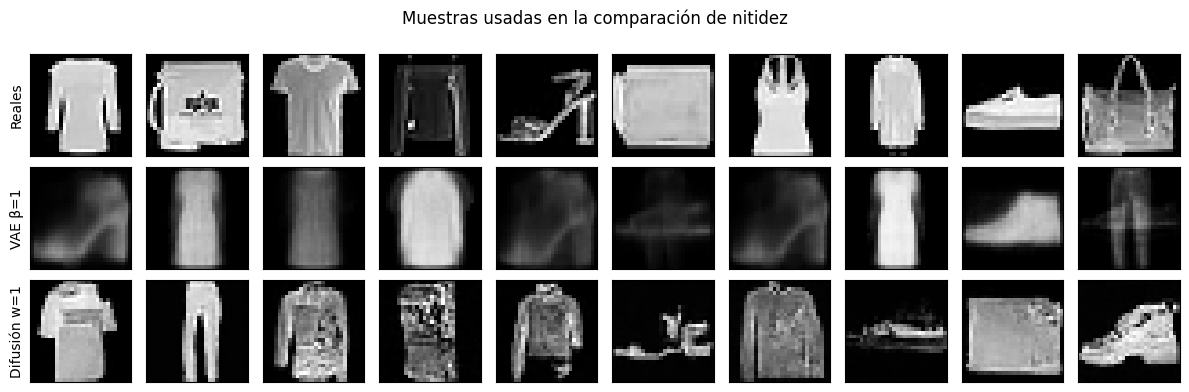

In [6]:
saved = torch.load(ROOT / "artifacts/task3/muestras_cfg.pt", map_location="cpu", weights_only=True)
diffusion_images = saved["w1"].float() / 255
assert diffusion_images.shape == (500, 1, 28, 28)
assert torch.equal(torch.bincount(saved["labels"]), torch.full((10,), 50))
real_images = torch.stack([val_set[i][0] for i in range(500)])
with torch.no_grad():
    z = torch.randn(500, LATENT_DIM, generator=torch.Generator().manual_seed(SEED))
    vae_images = vae.decode(z)
groups = {"Reales": real_images, "VAE β=1": vae_images, "Difusión w=1": diffusion_images}
sharpness = {name: horizontal_sharpness(imgs).item() for name, imgs in groups.items()}
for name, value in sharpness.items():
    print(f"{name:15s} | n=500 | nitidez={value:.6f}")

fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for row, (name, imgs) in enumerate(groups.items()):
    # Difusión está ordenada por clase: mostramos una imagen por clase.
    indices = range(0, 500, 50) if name == "Difusión w=1" else range(10)
    for col, idx in enumerate(indices):
        axes[row, col].imshow(imgs[idx, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(name)
fig.suptitle("Muestras usadas en la comparación de nitidez")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "comparacion.png", dpi=150)
plt.show()

## Task 4.1(b) — Tiempo de generación de 100 imágenes

«Sin guía» significa aquí $w=1$, la predicción condicional pura de la Task 3.3,
sin una segunda evaluación incondicional. Ambos modelos usan CPU, float32,
cuatro hilos y un lote de 100. Medimos la mediana de tres repeticiones después
de un calentamiento. Incluimos el sorteo del ruido y el muestreo; excluimos carga
de pesos, entrenamiento, gráficos y escritura. Son tiempos locales, no los
tiempos de la GPU usados en la Task 3.

El VAE evalúa su decoder una vez por lote (una vez por imagen). La difusión
evalúa la U-Net 1000 veces por lote (1000 veces por imagen); no son 1000
llamadas adicionales por cada imagen porque las 100 se procesan juntas.

In [7]:
unet = UNet().to(DEVICE).eval()
unet.load_state_dict(torch.load(ROOT / "artifacts/task3/unet_cfg.pt",
                               map_location=DEVICE, weights_only=True))
betas, alphas, alpha_bars = linear_schedule()
labels = torch.arange(10, device=DEVICE).repeat_interleave(10)

@torch.no_grad()
def generate_vae(generator):
    return vae.decode(torch.randn(100, LATENT_DIM, device=DEVICE, generator=generator))

@torch.no_grad()
def generate_diffusion(generator):
    return sample(unet, labels, 1, betas, alphas, alpha_bars, generator=generator)

# Calentamiento con las mismas formas de lote; no forma parte de los tiempos.
with torch.no_grad():
    generate_vae(torch.Generator(device=DEVICE).manual_seed(SEED))
    unet(torch.zeros(100, 1, 28, 28, device=DEVICE),
         torch.ones(100, dtype=torch.long, device=DEVICE), labels)

timings = {}
for name, generate in [("VAE", generate_vae), ("Difusión", generate_diffusion)]:
    durations = []
    for repeat in range(3):
        generator = torch.Generator(device=DEVICE).manual_seed(SEED + repeat)
        start = time.perf_counter()
        generated = generate(generator)
        durations.append(time.perf_counter() - start)
        assert generated.shape == (100, 1, 28, 28) and torch.isfinite(generated).all()
        print(f"{name}: repetición {repeat+1}, {durations[-1]:.6f} s", flush=True)
    timings[name] = {"repeticiones_s": durations, "mediana_s": statistics.median(durations)}
ratio = timings["Difusión"]["mediana_s"] / timings["VAE"]["mediana_s"]
print(f"Razón difusión/VAE: {ratio:.1f} veces")

VAE: repetición 1, 0.000261 s


VAE: repetición 2, 0.000319 s


VAE: repetición 3, 0.000291 s


Difusión: repetición 1, 56.237384 s


Difusión: repetición 2, 56.175745 s


Difusión: repetición 3, 56.362619 s


Razón difusión/VAE: 193006.9 veces


## Task 4.1(c) — Compensaciones observadas

In [8]:
analysis = (
    f"El VAE obtuvo nitidez **{sharpness['VAE β=1']:.6f}**, frente a "
    f"**{sharpness['Difusión w=1']:.6f}** de difusión y **{sharpness['Reales']:.6f}** "
    f"de las imágenes reales. La difusión conserva más variación local; esta métrica "
    f"también puede aumentar por ruido y no demuestra por sí sola calidad semántica. "
    f"En la figura, el VAE suaviza contornos y texturas, mientras la difusión conserva "
    f"más detalle. El VAE tarda **{timings['VAE']['mediana_s']:.6f} s** por 100 imágenes "
    f"y la difusión **{timings['Difusión']['mediana_s']:.3f} s**: "
    f"**{ratio:.1f} veces** más tiempo, con 1 frente a 1000 evaluaciones por lote.\n\n"
    f"El VAE prioriza velocidad a costa de nitidez: comprime a dos dimensiones y "
    f"su reconstrucción cuadrática favorece promedios. Su pérdida de validación pasó "
    f"de **{history['val_loss'][0]:.4f}** a **{history['val_loss'][-1]:.4f}**. "
    f"En la Task 3 la pérdida de difusión pasó de **0.1250** a **0.0408** en 30 épocas. "
    f"Ambas corridas convergieron sin un entrenamiento adversarial, pero sus pérdidas "
    f"tienen escalas distintas y una sola semilla no prueba estabilidad general.\n\n"
    f"Para acelerar difusión implementaría un muestreador de pasos reducidos, por "
    f"ejemplo DDIM con 50 pasos, y volvería a medir nitidez y fidelidad. Eso reduciría "
    f"las evaluaciones teóricas de 1000 a 50; no basta con truncar los últimos pasos "
    f"del muestreador ancestral ni implica una aceleración medida de 20 veces."
)
display(Markdown(analysis))

El VAE obtuvo nitidez **0.044968**, frente a **0.089737** de difusión y **0.088579** de las imágenes reales. La difusión conserva más variación local; esta métrica también puede aumentar por ruido y no demuestra por sí sola calidad semántica. En la figura, el VAE suaviza contornos y texturas, mientras la difusión conserva más detalle. El VAE tarda **0.000291 s** por 100 imágenes y la difusión **56.237 s**: **193006.9 veces** más tiempo, con 1 frente a 1000 evaluaciones por lote.

El VAE prioriza velocidad a costa de nitidez: comprime a dos dimensiones y su reconstrucción cuadrática favorece promedios. Su pérdida de validación pasó de **33.2291** a **28.3794**. En la Task 3 la pérdida de difusión pasó de **0.1250** a **0.0408** en 30 épocas. Ambas corridas convergieron sin un entrenamiento adversarial, pero sus pérdidas tienen escalas distintas y una sola semilla no prueba estabilidad general.

Para acelerar difusión implementaría un muestreador de pasos reducidos, por ejemplo DDIM con 50 pasos, y volvería a medir nitidez y fidelidad. Eso reduciría las evaluaciones teóricas de 1000 a 50; no basta con truncar los últimos pasos del muestreador ancestral ni implica una aceleración medida de 20 veces.

## Task 4.2(a) — Estimador insesgado

El fracaso significa escoger $k$ soluciones entre las $n-c$ incorrectas, sin
reemplazo. Por eso $\mathrm{pass@}k=1-\binom{n-c}{k}/\binom nk$.
Usamos un producto de cocientes en float64, sin factoriales grandes.

Para P2, $n=20$, $c=2$, $k=5$:

$$\binom{18}{5}=8568,\qquad\binom{20}{5}=15504,$$
$$\mathrm{pass@}5=1-\frac{8568}{15504}=\frac{17}{38}=0.4473684211.$$

In [9]:
counts = [0, 2, 5, 9, 14, 20]
ks = [1, 5, 10]
values = torch.tensor([[pass_at_k(20, c, k) for k in ks] for c in counts], dtype=torch.float64)
naive = torch.tensor([1 - (1 - c / 20) ** 5 for c in counts], dtype=torch.float64)
print("Problema | c | pass@1   | pass@5   | pass@10  | ingenuo@5 | diferencia@5")
for i, c in enumerate(counts):
    print(f"P{i+1:1d}       | {c:2d}| {values[i,0]:.6f} | {values[i,1]:.6f} | "
          f"{values[i,2]:.6f} | {naive[i]:.6f}  | {values[i,1]-naive[i]:.6f}")
print("Promedios:", ", ".join(f"pass@{k}={v:.6f}" for k, v in zip(ks, values.mean(0))))
min_k = next(k for k in range(1, 21) if pass_at_k(20, 2, k) > 0.9)
print(f"P2: menor k con pass@k > 0.9: {min_k}")
print(f"P2: pass@13={pass_at_k(20,2,13):.6f}, pass@14={pass_at_k(20,2,14):.6f}")
assert torch.all(naive <= values[:, 1] + 1e-15)

Problema | c | pass@1   | pass@5   | pass@10  | ingenuo@5 | diferencia@5
P1       |  0| 0.000000 | 0.000000 | 0.000000 | 0.000000  | 0.000000
P2       |  2| 0.100000 | 0.447368 | 0.763158 | 0.409510  | 0.037858
P3       |  5| 0.250000 | 0.806308 | 0.983746 | 0.762695  | 0.043613
P4       |  9| 0.450000 | 0.970201 | 0.999940 | 0.949672  | 0.020530
P5       | 14| 0.700000 | 0.999613 | 1.000000 | 0.997570  | 0.002043
P6       | 20| 1.000000 | 1.000000 | 1.000000 | 1.000000  | 0.000000
Promedios: pass@1=0.416667, pass@5=0.703915, pass@10=0.791141
P2: menor k con pass@k > 0.9: 14
P2: pass@13=0.889474, pass@14=0.921053


## Task 4.2(b) — Umbral para P2

Al cancelar los factoriales, para $1\le k\le18$:

$$\frac{\binom{18}{k}}{\binom{20}{k}}
=\frac{18!\,(20-k)!}{20!\,(18-k)!}
=\frac{(20-k)(19-k)}{380}.$$

Para $k=19,20$ no pueden elegirse tantas soluciones incorrectas y pass@k vale 1;
la misma expresión también da 1. Exigir pass@k > 0.9 equivale a
$(20-k)(19-k)<38$. Con $k=13$ el producto es 42 y pass@13 = 0.889474;
con $k=14$ es 30 y pass@14 = 0.921053. Como pass@k es monótono, **14 es el mínimo**.

## Task 4.2(c) — Comparación con la versión ingenua

Si $n-c\ge k$, cada factor no negativo cumple

$$\frac{n-c-i}{n-i}=1-\frac{c}{n-i}\le1-\frac cn.$$

Al multiplicar para $i=0,\ldots,k-1$ y restar de 1:

$$1-\prod_i\frac{n-c-i}{n-i}\ge1-(1-c/n)^k.$$

Si $n-c<k$, el estimador insesgado vale 1 y la desigualdad también se cumple.
En la tabla, P2 da 0.447368 frente a 0.409510; P3 da 0.806308 frente a
0.762695. La versión ingenua nunca excede a la insesgada. Modela intentos
independientes con reemplazo y trata c/n como una probabilidad exacta;
no es el estimador insesgado a partir de las 20 soluciones observadas.

## Task 4.2(d) — Agente con hasta diez intentos

No se puede afirmar que cada problema se resolverá a partir de una probabilidad.
Bajo el muestreo sin reemplazo de las 20 soluciones, **P1 no se resuelve** (0),
**P2** tiene probabilidad **0.763158**, **P3** **0.983746**, **P4** **0.999940**,
y **P5 y P6** tienen probabilidad **1**: hay menos de diez fallos disponibles.
Un verificador perfecto reconoce una solución correcta, pero no la genera.
Estas garantías del conjunto finito no garantizan el éxito de diez nuevas
generaciones independientes o de reintentos correlacionados con retroalimentación.

In [10]:
means = values.mean(0)
conclusion = (f"El promedio aumenta de **{means[0]:.6f}** en pass@1 a **{means[2]:.6f}** "
              f"en pass@10 (**{100*(means[2]-means[0]):.2f} puntos porcentuales**). "
              "El modelo produce soluciones útiles que no siempre aparecen al primer intento; "
              "muestrear y verificar ayuda, pero no corrige P1, donde no se observó ningún éxito.")
display(Markdown(conclusion))
results = {
    "semilla": SEED, "dispositivo": str(DEVICE), "sistema": platform.platform(),
    "torch": str(torch.__version__), "hilos": torch.get_num_threads(),
    "nitidez": sharpness, "tiempos": timings, "razon_tiempos": ratio,
    "evaluaciones_por_lote": {"VAE": 1, "Difusión": 1000},
    "analisis": analysis, "pass_at_k": values.tolist(), "ingenuo_5": naive.tolist(),
    "promedios": means.tolist(), "minimo_k_p2": min_k, "conclusion": conclusion,
}
(CHECKPOINT_DIR / "resultados.json").write_text(
    json.dumps(results, ensure_ascii=False, indent=2) + "\n")

El promedio aumenta de **0.416667** en pass@1 a **0.791141** en pass@10 (**37.45 puntos porcentuales**). El modelo produce soluciones útiles que no siempre aparecen al primer intento; muestrear y verificar ayuda, pero no corrige P1, donde no se observó ningún éxito.

2934